In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    PolynomialFeatures,
    RobustScaler,
    QuantileTransformer,
)

#modelos arvores
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

from src.config import DADOS_LIMPOS
from src.auxiliares import dataframe_coeficientes
from src.graficos import (
    plot_coeficientes,
    plot_comparar_metricas_modelos,
    plot_residuos_estimador,
)
from src.models import (
    organiza_resultados,
    treinar_e_validar_modelo_regressao,
    grid_search_cv_regressor,
)

RANDOM_STATE = 42

In [2]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,median_income_cat,rooms_per_household,population_per_household,bedrooms_per_room
0,-122.230003,37.880001,41,880,129,322,126,8.3252,452600,NEAR BAY,5,6.984127,2.555556,0.146591
1,-122.220001,37.860001,21,7099,1106,2401,1138,8.3014,358500,NEAR BAY,5,6.238137,2.109842,0.155797
2,-122.260002,37.840000,42,2555,665,1206,595,2.0804,226700,NEAR BAY,2,4.294117,2.026891,0.260274
3,-122.260002,37.849998,50,1120,283,697,264,2.1250,140000,NEAR BAY,2,4.242424,2.640152,0.252679
4,-122.260002,37.840000,50,2239,455,990,419,1.9911,158700,NEAR BAY,2,5.343676,2.362768,0.203216


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17564 entries, 0 to 17563
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   longitude                 17564 non-null  float32 
 1   latitude                  17564 non-null  float32 
 2   housing_median_age        17564 non-null  int8    
 3   total_rooms               17564 non-null  int16   
 4   total_bedrooms            17564 non-null  int16   
 5   population                17564 non-null  int16   
 6   households                17564 non-null  int16   
 7   median_income             17564 non-null  float32 
 8   median_house_value        17564 non-null  int32   
 9   ocean_proximity           17564 non-null  category
 10  median_income_cat         17564 non-null  int64   
 11  rooms_per_household       17564 non-null  float32 
 12  population_per_household  17564 non-null  float32 
 13  bedrooms_per_room         17564 non-null  floa

In [4]:
coluna_target = ["median_house_value"]

coluna_one_hot_encoder = ["ocean_proximity"]

coluna_ordinal_encoder = ["median_income_cat"]

In [5]:
colunas_robust_scaler = df.columns.difference(coluna_target + coluna_one_hot_encoder + coluna_ordinal_encoder)

colunas_robust_scaler

Index(['bedrooms_per_room', 'households', 'housing_median_age', 'latitude',
       'longitude', 'median_income', 'population', 'population_per_household',
       'rooms_per_household', 'total_bedrooms', 'total_rooms'],
      dtype='object')

In [6]:
pipeline_robust = Pipeline(steps=[
    ("robust_scaler", RobustScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False))
])

preprocessamento = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories="auto"), coluna_ordinal_encoder),
        ("one_hot", OneHotEncoder(drop="first"), coluna_one_hot_encoder),
        ("robust_scaler_poly", pipeline_robust, colunas_robust_scaler),
    ],
)

preprocessamento_arvore = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories="auto"), coluna_ordinal_encoder),
        ("one_hot", OneHotEncoder(drop="first"), coluna_one_hot_encoder),
    ],
    remainder="passthrough"
)

In [7]:
X = df.drop(columns=coluna_target)
y = df[coluna_target]

In [8]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_income_cat,rooms_per_household,population_per_household,bedrooms_per_room
0,-122.230003,37.880001,41,880,129,322,126,8.3252,NEAR BAY,5,6.984127,2.555556,0.146591
1,-122.220001,37.860001,21,7099,1106,2401,1138,8.3014,NEAR BAY,5,6.238137,2.109842,0.155797
2,-122.260002,37.840000,42,2555,665,1206,595,2.0804,NEAR BAY,2,4.294117,2.026891,0.260274
3,-122.260002,37.849998,50,1120,283,697,264,2.1250,NEAR BAY,2,4.242424,2.640152,0.252679
4,-122.260002,37.840000,50,2239,455,990,419,1.9911,NEAR BAY,2,5.343676,2.362768,0.203216


In [9]:
y.head()

,median_house_value
0,452600
1,358500
2,226700
3,140000
4,158700


In [10]:
regressors = {
    "DummyRegressor": {
        "preprocessor": None,
        "regressor": DummyRegressor(strategy="mean"),
        "target_transformer": None,
    },
    "LinearRegression": {
        "preprocessor": preprocessamento,
        "regressor": LinearRegression(),
        "target_transformer": None,
    },
    "LinearRegression_target": {
        "preprocessor": preprocessamento,
        "regressor": LinearRegression(),
        "target_transformer": QuantileTransformer(output_distribution="normal"),
    },
    "Ridge_best": {
        "preprocessor": preprocessamento,
        "regressor": Ridge(alpha=10),
        "target_transformer": QuantileTransformer(output_distribution="normal"),
    },

    #arvores
    "DecisionTreeRegressor": {
        "preprocessor": preprocessamento_arvore,
        "regressor": DecisionTreeRegressor(random_state=RANDOM_STATE),
        "target_transformer": None,
    },

    "RandomForestRegressor": {
        "preprocessor": preprocessamento_arvore,
        "regressor": RandomForestRegressor(random_state=RANDOM_STATE),
        "target_transformer": None,
    },

    "XGBRegressor": {
        "preprocessor": preprocessamento_arvore,
        "regressor": XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        "target_transformer": None,
    },

    "LGBMRegressor": {
        "preprocessor": preprocessamento_arvore,
        "regressor": LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        "target_transformer": None,
    },
}


resultados = {
    nome_modelo: treinar_e_validar_modelo_regressao(X, y, **regressor)
    for nome_modelo, regressor in regressors.items()
}

df_resultados = organiza_resultados(resultados)

df_resultados

/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/base.py:1473: DataCon

,model,fit_time,score_time,test_r2,test_neg_mean_absolute_error,test_neg_root_mean_squared_error,time_seconds
0,DummyRegressor,0.00388,0.006361,-0.000081,-77516.042766,-96239.705692,0.01024
1,DummyRegressor,0.003819,0.004452,-0.000146,-75787.787194,-95217.629397,0.00827
2,DummyRegressor,0.004084,0.004737,-0.001737,-76753.598961,-96253.253947,0.008821
3,DummyRegressor,0.003052,0.004761,-0.000101,-76837.804811,-95983.885799,0.007814
4,DummyRegressor,0.003378,0.003686,-0.000114,-76617.245449,-96182.764729,0.007064
5,LinearRegression,0.301834,0.020911,0.716586,-35303.554333,-51232.750906,0.322745
6,LinearRegression,0.361277,0.014133,0.721499,-35702.821852,-50245.695244,0.375409
7,LinearRegression,0.204389,0.014637,0.700947,-37686.232664,-52591.125772,0.219026
8,LinearRegression,0.245703,0.011526,0.726099,-35706.191301,-50231.16459,0.257229
9,LinearRegression,0.261723,0.010739,0.720455,-36226.297106,-50850.862239,0.272462


In [11]:
df_resultados.groupby("model").mean().sort_values(by="test_neg_root_mean_squared_error")

,fit_time,score_time,test_r2,test_neg_mean_absolute_error,test_neg_root_mean_squared_error,time_seconds
model,,,,,,
DummyRegressor,0.003643,0.004799,-0.000436,-76702.495836,-95975.447913,0.008442
DecisionTreeRegressor,0.174407,0.004865,0.57929,-41099.684732,-62223.439296,0.179272
LinearRegression_target,0.183168,0.0111,0.715704,-35590.448209,-51149.725455,0.194268
LinearRegression,0.274985,0.014389,0.717117,-36125.019451,-51030.31975,0.289374
Ridge_best,0.105686,0.014874,0.723189,-35343.618824,-50466.450763,0.12056
RandomForestRegressor,11.070224,0.059396,0.794677,-29132.244972,-43476.799188,11.12962
XGBRegressor,0.255721,0.007637,0.820168,-27349.076724,-40687.764203,0.263358
LGBMRegressor,0.350752,0.010163,0.822636,-27413.392316,-40406.68304,0.360915


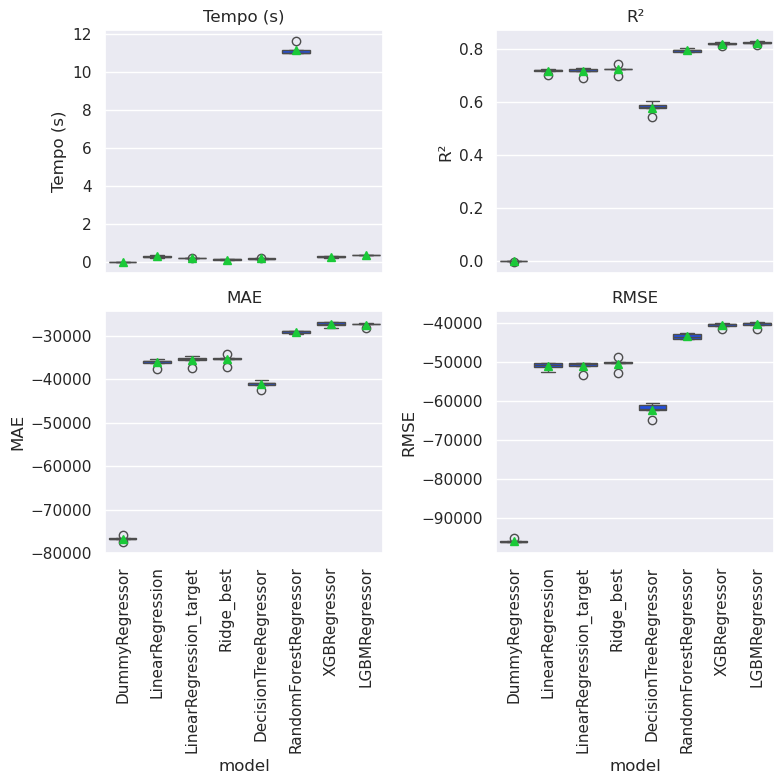

In [12]:
plot_comparar_metricas_modelos(df_resultados)

In [13]:
# param grid para o modelo em estudo
param_grid = {
    "reg__max_depth": [10, 20],  # Profundidade máxima da árvore (<=0 significa sem limite)
    # "reg__num_leaves": [20, 31, 50],  # Número máximo de folhas por árvore
    # "reg__min_child_samples": [20, 50],  # Mínimo de amostras em um nó folha
    # "reg__min_split_gain": [0.0, 0.1, 0.3],  # Redução mínima de perda para divisão
    "reg__subsample": [0.6, 0.8, 1.0],  # Proporção de amostras usadas para cada árvore
    "reg__colsample_bytree": [0.6, 0.8, 1.0],  # Proporção de features para construção de cada árvore
    "reg__learning_rate": [0.05, 0.1],  # Taxa de aprendizado
    "reg__n_estimators": [100, 500],  # Número de árvores
    "reg__reg_alpha": [0.0, 1.0, 5.0],  # Regularização L1
    "reg__reg_lambda": [0.0, 1.0, 5.0],  # Regularização L2
}

#google scholar

In [14]:
grid_search = grid_search_cv_regressor(
    regressor=LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    preprocessor=preprocessamento_arvore,
    target_transformer=None, 
    param_grid=param_grid
)

grid_search

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ordinal_encoder',
                                                                         OrdinalEncoder(),
                                                                         ['median_income_cat']),
                                                                        ('one_hot',
                                                                         OneHotEncoder(drop='first'),
                                                                         ['ocean_proximity'])])),
                                       ('reg',
                                        LGBMRegressor(n_jobs=-1,
                                                      random_state=42,
                                                      verbose=-1))]),
             n_job...,
             param_grid={'reg__colsample_bytree': [0.6, 0.8, 1.0],
                         'reg__learning_rate': [0.05, 0.1],
                         'reg__max_depth': [10, 20],
                         'reg__n_estimators': [100, 500],
                         'reg__reg_alpha': [0.0, 1.0, 5.0],
                         'reg__reg_lambda': [0.0, 1.0, 5.0],
                         'reg__subsample': [0.6, 0.8, 1.0]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [15]:
grid_search.fit(X, y)

Fitting 5 folds for each of 648 candidates, totalling 3240 fits


/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/utils/validation.py:1339: D

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('ordinal_encoder',
                                                                         OrdinalEncoder(),
                                                                         ['median_income_cat']),
                                                                        ('one_hot',
                                                                         OneHotEncoder(drop='first'),
                                                                         ['ocean_proximity'])])),
                                       ('reg',
                                        LGBMRegressor(n_jobs=-1,
                                                      random_state=42,
                                                      verbose=-1))]),
             n_job...,
             param_grid={'reg__colsample_bytree': [0.6, 0.8, 1.0],
                         'reg__learning_rate': [0.05, 0.1],
                         'reg__max_depth': [10, 20],
                         'reg__n_estimators': [100, 500],
                         'reg__reg_alpha': [0.0, 1.0, 5.0],
                         'reg__reg_lambda': [0.0, 1.0, 5.0],
                         'reg__subsample': [0.6, 0.8, 1.0]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [16]:
grid_search.best_params_

{'reg__colsample_bytree': 1.0,
 'reg__learning_rate': 0.1,
 'reg__max_depth': 10,
 'reg__n_estimators': 500,
 'reg__reg_alpha': 1.0,
 'reg__reg_lambda': 5.0,
 'reg__subsample': 0.6}

In [18]:
grid_search.best_score_

-38543.48895463014

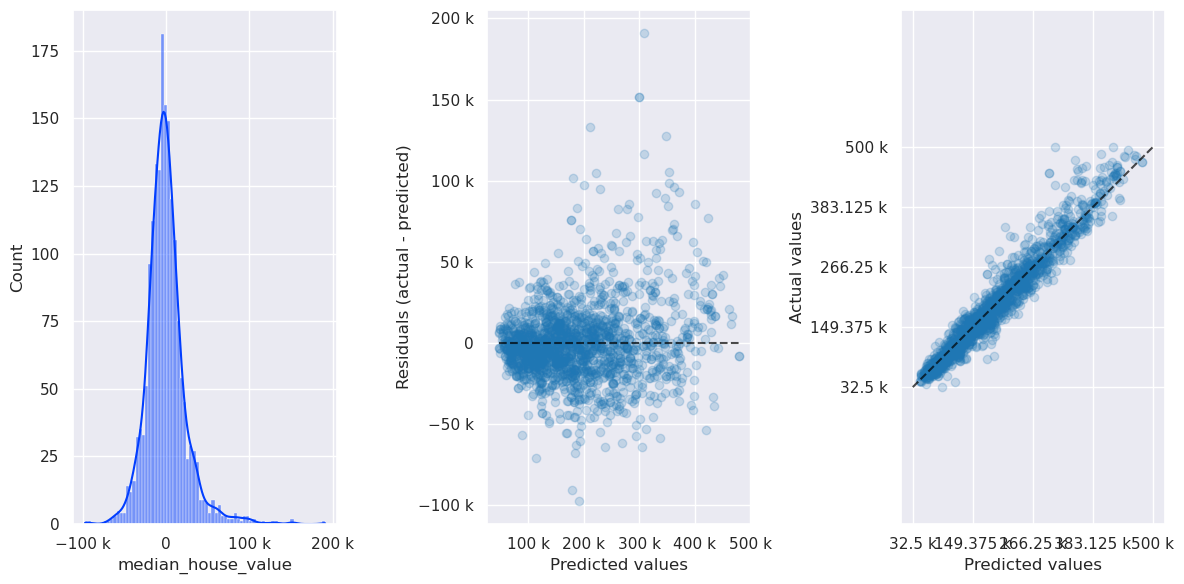

In [20]:
plot_residuos_estimador(grid_search.best_estimator_, X, y.squeeze(), fracao_amostra=0.1, eng_formatter=True)

https://scikit-learn.org/stable/model_persistence.html

In [ ]:
# dump(grid_search.best_estimator_, MODELO_FINAL)